In [2]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


In [3]:
!pip install -q rdkit torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 69.5 MB/s eta 0:00:00


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from rdkit import Chem
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, global_mean_pool

In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/deepchem/deepchem/master/examples/tutorials/00_Loading_a_Dataset.ipynb"

In [6]:
!wget -q https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv

In [7]:
df = pd.read_csv("delaney-processed.csv")

print(df.shape)
df.head()

(1128, 10)


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [8]:
print(df.columns.tolist())
df.info()

['Compound ID', 'ESOL predicted log solubility in mols per litre', 'Minimum Degree', 'Molecular Weight', 'Number of H-Bond Donors', 'Number of Rings', 'Number of Rotatable Bonds', 'Polar Surface Area', 'measured log solubility in mols per litre', 'smiles']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 10 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Compound ID                                      1128 non-null   object 
 1   ESOL predicted log solubility in mols per litre  1128 non-null   float64
 2   Minimum Degree                                   1128 non-null   int64  
 3   Molecular Weight                                 1128 non-null   float64
 4   Number of H-Bond Donors                          1128 non-null   int64  
 5   Number of Rings                                  1128 non-null   int64  
 6   Number 

## Molecular Graph Featurization

In [9]:
import torch
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski
from torch_geometric.data import Data

def smiles_to_graph(smiles, target=None):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    # 1. Node features (9 atom descriptors)
    atom_features = []
    for atom in mol.GetAtoms():
        atom_features.append([
            atom.GetAtomicNum(),
            atom.GetDegree(),
            atom.GetFormalCharge(),
            int(atom.GetHybridization()),
            int(atom.GetIsAromatic()),
            atom.GetTotalNumHs(),
            atom.GetNumRadicalElectrons(),
            int(atom.IsInRing()),
            int(atom.GetChiralTag())
        ])
    x = torch.tensor(atom_features, dtype=torch.float)

    # 2. Edge connections and weights
    edge_indices, edge_weights = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        w = float(bond.GetBondTypeAsDouble())
        edge_indices += [[i, j], [j, i]]
        edge_weights += [w, w]

    if len(edge_indices) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_weight = torch.empty((0,), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
        edge_weight = torch.tensor(edge_weights, dtype=torch.float)

    # 3. Five Global Physical Descriptors (MW, TPSA, LogP, RotBonds, H-Donors)
    tabular = torch.tensor([[
        Descriptors.MolWt(mol),
        Descriptors.TPSA(mol),
        Descriptors.MolLogP(mol),
        float(Lipinski.NumRotatableBonds(mol)),
        float(Lipinski.NumHDonors(mol))
    ]], dtype=torch.float)

    data = Data(x=x, edge_index=edge_index, edge_weight=edge_weight, tabular=tabular)
    if target is not None:
        data.y = torch.tensor([[target]], dtype=torch.float)
    return data

## Dataset Conversion & Train/Test Split

In [10]:
from torch_geometric.loader import DataLoader

data_list = [
    smiles_to_graph(s, t)
    for s, t in zip(df["smiles"], df["measured log solubility in mols per litre"])
    if smiles_to_graph(s, t) is not None
]

train_len = int(0.8 * len(data_list))
test_len = len(data_list) - train_len
train_data, test_data = torch.utils.data.random_split(
    data_list, [train_len, test_len], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print(f"Total valid molecular graphs: {len(data_list)}")
print(f"Training samples: {len(train_data)} | Testing samples: {len(test_data)}")

Total valid molecular graphs: 1128
Training samples: 902 | Testing samples: 226


## GNN Model Architecture & Setup

In [11]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool

class HybridMolecularGNN(nn.Module):
    def __init__(self, in_channels=9, hidden_dim=64, num_tabular=5):
        super().__init__()
        # Graph branch
        self.conv1 = GCNConv(in_channels, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.conv3 = GCNConv(hidden_dim, hidden_dim)
        self.bn3 = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(0.2)

        # Tabular physical features branch
        self.bn_tabular = nn.BatchNorm1d(num_tabular)

        # Combined Prediction Head: (64*2 graph features) + 5 tabular = 133
        self.fc1 = nn.Linear(hidden_dim * 2 + num_tabular, 64)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x, edge_index, edge_weight, batch, tabular):
        # 1. Message passing
        x = F.relu(self.bn1(self.conv1(x, edge_index, edge_weight)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.conv2(x, edge_index, edge_weight)))
        x = self.dropout(x)
        x = F.relu(self.bn3(self.conv3(x, edge_index, edge_weight)))

        # 2. Dual pooling: 128 features
        pooled = torch.cat([global_mean_pool(x, batch), global_max_pool(x, batch)], dim=1)

        # 3. Normalize tabular: 5 features
        tab_norm = self.bn_tabular(tabular)

        # 4. Concatenate graph + tabular = 133 features
        combined = torch.cat([pooled, tab_norm], dim=1)

        x = F.relu(self.fc1(combined))
        x = self.dropout(x)
        return self.fc2(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = HybridMolecularGNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.MSELoss()

print(f"Hybrid Model initialized on: {device}")

Hybrid Model initialized on: cuda


## Training

In [12]:
import copy

best_test_rmse = float("inf")
best_model_weights = None

print("Training Hybrid GNN architecture...")
for epoch in range(1, 101):
    model.train()
    total_train_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * batch.num_graphs

    model.eval()
    total_test_mse = 0
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            preds = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
            total_test_mse += criterion(preds, batch.y).item() * batch.num_graphs

    epoch_test_rmse = (total_test_mse / len(test_data)) ** 0.5

    if epoch_test_rmse < best_test_rmse:
        best_test_rmse = epoch_test_rmse
        best_model_weights = copy.deepcopy(model.state_dict())

    if epoch % 20 == 0 or epoch == 1:
        epoch_train_rmse = (total_train_loss / len(train_data)) ** 0.5
        print(f"Epoch {epoch:03d} | Train RMSE: {epoch_train_rmse:.4f} | Current Test RMSE: {epoch_test_rmse:.4f}")

model.load_state_dict(best_model_weights)
print(f"\nBest Test RMSE Achieved: {best_test_rmse:.4f} logS")

Training Hybrid GNN architecture...


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


Epoch 001 | Train RMSE: 2.4171 | Current Test RMSE: 2.4233
Epoch 020 | Train RMSE: 0.8819 | Current Test RMSE: 1.0079
Epoch 040 | Train RMSE: 0.8890 | Current Test RMSE: 0.6832
Epoch 060 | Train RMSE: 0.7565 | Current Test RMSE: 0.6426
Epoch 080 | Train RMSE: 0.7865 | Current Test RMSE: 0.8823
Epoch 100 | Train RMSE: 0.7546 | Current Test RMSE: 0.8211

Best Test RMSE Achieved: 0.6036 logS


## Evaluation on Test Set

In [13]:
model.eval()
test_mse = 0
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        preds = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
        test_mse += criterion(preds, batch.y).item() * batch.num_graphs

test_rmse = (test_mse / len(test_data)) ** 0.5
print(f"Final Test RMSE: {test_rmse:.4f} logS")

Final Test RMSE: 0.6036 logS


## Live Prediction on New Molecules

In [14]:
def predict(smiles_str):
    model.eval()
    data = smiles_to_graph(smiles_str)
    if data is None:
        return "Invalid SMILES"
    data = data.to(device)
    batch = torch.zeros(data.x.size(0), dtype=torch.long, device=device)
    with torch.no_grad():
        val = model(data.x, data.edge_index, data.edge_weight, batch, data.tabular).item()
    return round(val, 3)

print("Prediction Tests:")
print("Ethanol (CCO):", predict("CCO"), "logS")
print("Aspirin (CC(=O)Oc1ccccc1C(=O)O):", predict("CC(=O)Oc1ccccc1C(=O)O"), "logS")

Prediction Tests:
Ethanol (CCO): 0.958 logS
Aspirin (CC(=O)Oc1ccccc1C(=O)O): -1.9 logS


Sample Test Set Predictions vs Actuals:
 Actual logS  Predicted logS  Abs Error
      -2.600          -2.607      0.007
      -3.500          -3.163      0.337
      -2.210          -1.716      0.494
      -1.210          -0.835      0.375
      -5.210          -5.735      0.525
      -8.176          -7.511      0.665
      -4.650          -4.410      0.240
      -1.600          -1.803      0.203
      -1.990          -1.541      0.449
      -2.878          -2.458      0.420


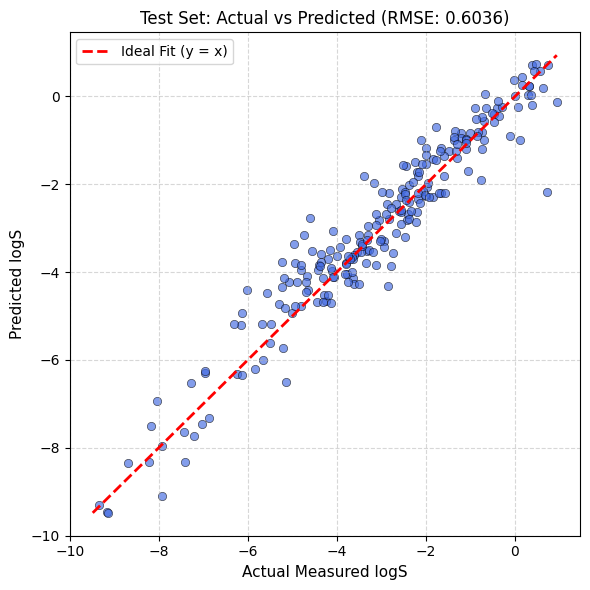

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# 1. Collect actual vs predicted values across the test set
model.eval()
actuals, predictions = [], []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        preds = model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
        actuals.extend(batch.y.view(-1).cpu().numpy())
        predictions.extend(preds.view(-1).cpu().numpy())

actuals = np.array(actuals)
predictions = np.array(predictions)

# 2. Show side-by-side comparison for 10 sample test molecules
comp_df = pd.DataFrame({
    "Actual logS": np.round(actuals[:10], 3),
    "Predicted logS": np.round(predictions[:10], 3),
    "Abs Error": np.round(np.abs(actuals[:10] - predictions[:10]), 3)
})
print("Sample Test Set Predictions vs Actuals:")
print(comp_df.to_string(index=False))

# 3. Plot Actual vs. Predicted scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(actuals, predictions, alpha=0.65, color="royalblue", edgecolors="k", linewidth=0.5)
min_val = min(actuals.min(), predictions.min())
max_val = max(actuals.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Ideal Fit (y = x)")

plt.xlabel("Actual Measured logS", fontsize=11)
plt.ylabel("Predicted logS", fontsize=11)
plt.title(f"Test Set: Actual vs Predicted (RMSE: {best_test_rmse:.4f})", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Train using FreeSolv and Lipophicility

## Cell 1: Define the Reusable Training Engine

In [16]:
import copy
import torch
import torch.nn as nn
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader

def train_property_model(dataset_name, epochs=80, lr=0.001):
    print(f"\n==========================================")
    print(f" Loading & Featurizing: {dataset_name}")
    print(f"==========================================")
    raw_dataset = MoleculeNet(root="data", name=dataset_name)

    # Featurize every molecule with our hybrid pipeline
    graph_list = []
    for item in raw_dataset:
        if item.y.numel() == 0 or torch.isnan(item.y).any():
            continue
        g = smiles_to_graph(item.smiles, float(item.y.view(-1)[0].item()))
        if g is not None:
            graph_list.append(g)

    # 80/20 Train/Test Split
    torch.manual_seed(42)
    split = int(0.8 * len(graph_list))
    idx = torch.randperm(len(graph_list)).tolist()
    train_set = [graph_list[i] for i in idx[:split]]
    test_set = [graph_list[i] for i in idx[split:]]

    # drop_last=True prevents a single-molecule batch that breaks BatchNorm1d
    train_ldr = DataLoader(train_set, batch_size=32, shuffle=True, drop_last=True)
    test_ldr = DataLoader(test_set, batch_size=32, shuffle=False)

    # Initialize a clean Hybrid GNN instance
    prop_model = HybridMolecularGNN().to(device)
    optimizer = torch.optim.Adam(prop_model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.MSELoss()

    best_rmse = float("inf")
    best_weights = None

    for epoch in range(1, epochs + 1):
        prop_model.train()
        for batch in train_ldr:
            batch = batch.to(device)
            optimizer.zero_grad()
            preds = prop_model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
            loss = loss_fn(preds, batch.y)
            loss.backward()
            optimizer.step()

        prop_model.eval()
        mse = 0
        with torch.no_grad():
            for batch in test_ldr:
                batch = batch.to(device)
                preds = prop_model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
                mse += loss_fn(preds, batch.y).item() * batch.num_graphs

        rmse = (mse / len(test_set)) ** 0.5
        if rmse < best_rmse:
            best_rmse = rmse
            best_weights = copy.deepcopy(prop_model.state_dict())

        if epoch % 20 == 0 or epoch == epochs:
            print(f"Epoch {epoch:03d}/{epochs:03d} | Test RMSE: {rmse:.4f}")

    prop_model.load_state_dict(best_weights)
    print(f"\n--> {dataset_name} Done! Best Test RMSE: {best_rmse:.4f}")
    return prop_model, best_rmse

## Cell 2: Train Model 2 on FreeSolv (Hydration Free Energy)

In [17]:
# FreeSolv: ~642 small organic molecules (evaluates hydration free energy in kcal/mol)
freesolv_model, freesolv_rmse = train_property_model("FreeSolv", epochs=80)


 Loading & Featurizing: FreeSolv


Processing...
Done!
/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


Epoch 020/080 | Test RMSE: 1.4527
Epoch 040/080 | Test RMSE: 1.3383
Epoch 060/080 | Test RMSE: 1.3105
Epoch 080/080 | Test RMSE: 1.1644

--> FreeSolv Done! Best Test RMSE: 1.1418


## Cell 3: Train Model 3 on Lipophilicity (Membrane Permeability)

In [23]:
# Lipophilicity: ~4,200 drug-like molecules from ChEMBL (evaluates logD7.4)
lipo_model, lipo_rmse = train_property_model("Lipo", epochs=60)


 Loading & Featurizing: Lipo


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


Epoch 020/060 | Test RMSE: 0.9774
Epoch 040/060 | Test RMSE: 0.8100
Epoch 060/060 | Test RMSE: 0.7428

--> Lipo Done! Best Test RMSE: 0.7369


## Cell 4: Multi-Property Benchmark Summary Table

In [24]:
import pandas as pd

summary_df = pd.DataFrame({
    "Benchmark Dataset": ["Delaney ESOL", "FreeSolv (SAMPL)", "Lipophilicity (ChEMBL)"],
    "Target Property": ["Aqueous Solubility (logS)", "Hydration Free Energy (ΔGhyd)", "Distribution Ratio (logD7.4)"],
    "Physical Unit": ["log10(mol/L)", "kcal/mol", "log10(ratio)"],
    "Best Test RMSE": [f"{best_test_rmse:.4f}", f"{freesolv_rmse:.4f}", f"{lipo_rmse:.4f}"]
})

print("=== Multi-Property Hybrid GNN Benchmark ===")
print(summary_df.to_string(index=False))

=== Multi-Property Hybrid GNN Benchmark ===
     Benchmark Dataset               Target Property Physical Unit Best Test RMSE
          Delaney ESOL     Aqueous Solubility (logS)  log10(mol/L)         0.6036
      FreeSolv (SAMPL) Hydration Free Energy (ΔGhyd)      kcal/mol         1.1418
Lipophilicity (ChEMBL)  Distribution Ratio (logD7.4)  log10(ratio)         0.7369


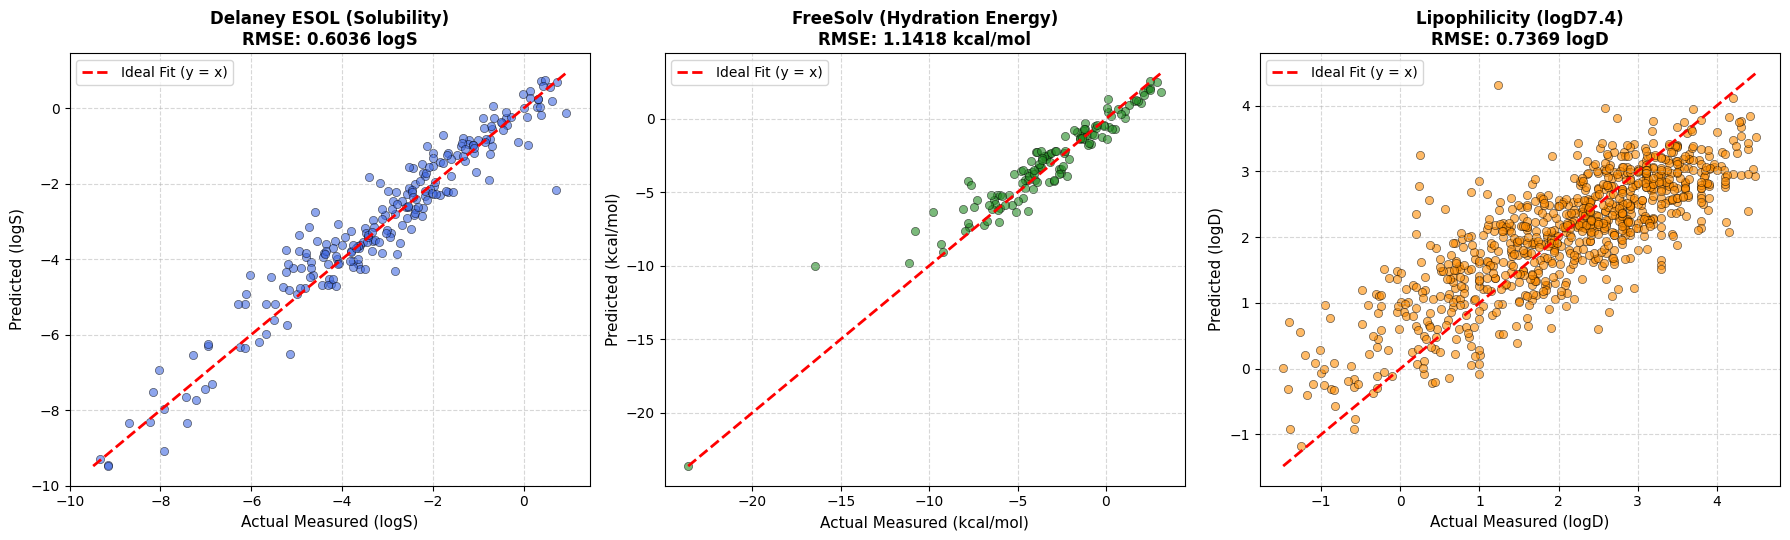

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def get_actuals_and_preds(target_model, data_loader):
    target_model.eval()
    actuals, predictions = [], []
    with torch.no_grad():
        for batch in data_loader:
            batch = batch.to(device)
            preds = target_model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
            actuals.extend(batch.y.view(-1).cpu().numpy())
            predictions.extend(preds.view(-1).cpu().numpy())
    return np.array(actuals), np.array(predictions)

# Helper to reconstruct test loader for FreeSolv & Lipo
def get_eval_loader(dataset_name):
    raw_dataset = MoleculeNet(root="data", name=dataset_name)
    graph_list = []
    for item in raw_dataset:
        if item.y.numel() == 0 or torch.isnan(item.y).any():
            continue
        g = smiles_to_graph(item.smiles, float(item.y.view(-1)[0].item()))
        if g is not None:
            graph_list.append(g)
    torch.manual_seed(42)
    split = int(0.8 * len(graph_list))
    idx = torch.randperm(len(graph_list)).tolist()
    test_set = [graph_list[i] for i in idx[split:]]
    return DataLoader(test_set, batch_size=32, shuffle=False)

# Collect predictions for all 3 models
esol_act, esol_pred = get_actuals_and_preds(model, test_loader)
freesolv_act, freesolv_pred = get_actuals_and_preds(freesolv_model, get_eval_loader("FreeSolv"))
lipo_act, lipo_pred = get_actuals_and_preds(lipo_model, get_eval_loader("Lipo"))

# 3-Panel Comparison Figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

benchmarks = [
    (axes[0], esol_act, esol_pred, "Delaney ESOL (Solubility)", f"RMSE: {best_test_rmse:.4f} logS", "royalblue", "logS"),
    (axes[1], freesolv_act, freesolv_pred, "FreeSolv (Hydration Energy)", f"RMSE: {freesolv_rmse:.4f} kcal/mol", "forestgreen", "kcal/mol"),
    (axes[2], lipo_act, lipo_pred, "Lipophilicity (logD7.4)", f"RMSE: {lipo_rmse:.4f} logD", "darkorange", "logD")
]

for ax, actual, pred, title, sub, color, unit in benchmarks:
    ax.scatter(actual, pred, alpha=0.6, color=color, edgecolors="k", linewidth=0.5, s=35)
    min_v = min(actual.min(), pred.min())
    max_v = max(actual.max(), pred.max())
    ax.plot([min_v, max_v], [min_v, max_v], "r--", lw=2, label="Ideal Fit (y = x)")

    ax.set_title(f"{title}\n{sub}", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"Actual Measured ({unit})", fontsize=11)
    ax.set_ylabel(f"Predicted ({unit})", fontsize=11)
    ax.legend(loc="upper left")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ADME Drug Discovery Card


  PHARMACOKINETIC & ADME CARD: ASPIRIN


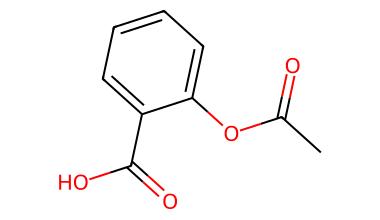

SMILES : CC(=O)Oc1ccccc1C(=O)O

--- 1. Multi-Property Hybrid GNN Predictions ---
  • Aqueous Solubility (logS)      : -1.900 log10(mol/L)
  • Hydration Free Energy (ΔGhyd) : -9.206 kcal/mol
  • Lipophilicity (logD7.4)        : -0.331

--- 2. Medicinal Chemistry & Drug-Likeness (RDKit) ---
  • QED Drug-Likeness Score       : 0.550 / 1.000
  • Lipinski's Rule of 5           : PASSED (Oral Drug-like)
  • Molecular Weight              : 180.16 g/mol
  • Polar Surface Area (TPSA)     : 63.60 Å²
  • Rotatable Bonds               : 2


  PHARMACOKINETIC & ADME CARD: CAFFEINE


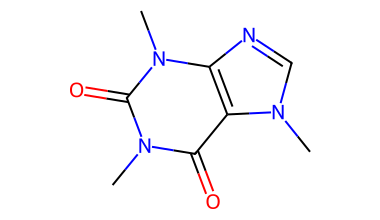

SMILES : CN1C=NC2=C1C(=O)N(C(=O)N2C)C

--- 1. Multi-Property Hybrid GNN Predictions ---
  • Aqueous Solubility (logS)      : -1.181 log10(mol/L)
  • Hydration Free Energy (ΔGhyd) : -10.324 kcal/mol
  • Lipophilicity (logD7.4)        : -0.476

--- 2. Medicinal Chemistry & Drug-Likeness (RDKit) ---
  • QED Drug-Likeness Score       : 0.538 / 1.000
  • Lipinski's Rule of 5           : PASSED (Oral Drug-like)
  • Molecular Weight              : 194.19 g/mol
  • Polar Surface Area (TPSA)     : 61.82 Å²
  • Rotatable Bonds               : 0


  PHARMACOKINETIC & ADME CARD: IBUPROFEN


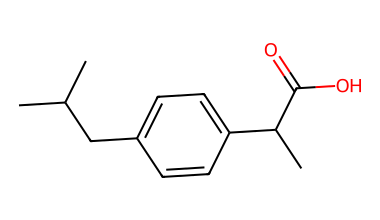

SMILES : CC(C)Cc1ccc(cc1)C(C)C(=O)O

--- 1. Multi-Property Hybrid GNN Predictions ---
  • Aqueous Solubility (logS)      : -3.126 log10(mol/L)
  • Hydration Free Energy (ΔGhyd) : -6.497 kcal/mol
  • Lipophilicity (logD7.4)        : +0.994

--- 2. Medicinal Chemistry & Drug-Likeness (RDKit) ---
  • QED Drug-Likeness Score       : 0.822 / 1.000
  • Lipinski's Rule of 5           : PASSED (Oral Drug-like)
  • Molecular Weight              : 206.28 g/mol
  • Polar Surface Area (TPSA)     : 37.30 Å²
  • Rotatable Bonds               : 4



In [27]:
from rdkit import Chem
from rdkit.Chem import Draw, QED, Descriptors, Lipinski
from IPython.display import display

def run_adme_profiler(smiles_str, mol_name="Candidate Molecule"):
    mol = Chem.MolFromSmiles(smiles_str)
    if mol is None:
        print(f"Error: Invalid SMILES string '{smiles_str}'")
        return

    # 1. Featurize graph & tabular input
    data = smiles_to_graph(smiles_str)
    data = data.to(device)
    batch_idx = torch.zeros(data.x.size(0), dtype=torch.long, device=device)

    # 2. Query all 3 trained models simultaneously
    model.eval()
    freesolv_model.eval()
    lipo_model.eval()

    with torch.no_grad():
        pred_sol = model(data.x, data.edge_index, data.edge_weight, batch_idx, data.tabular).item()
        pred_free = freesolv_model(data.x, data.edge_index, data.edge_weight, batch_idx, data.tabular).item()
        pred_lipo = lipo_model(data.x, data.edge_index, data.edge_weight, batch_idx, data.tabular).item()

    # 3. Calculate Medicinal Chemistry & Drug-Likeness Metrics
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    tpsa = Descriptors.TPSA(mol)
    rot_bonds = Lipinski.NumRotatableBonds(mol)
    qed_score = QED.qed(mol)

    # Lipinski's Rule of 5 evaluation (oral bioavailability criterion)
    violations = 0
    if mw > 500: violations += 1
    if logp > 5: violations += 1
    if hbd > 5: violations += 1
    if hba > 10: violations += 1
    ro5_status = "PASSED (Oral Drug-like)" if violations <= 1 else f"FAILED ({violations} violations)"

    # 4. Display 2D Structure Drawing
    print(f"\n{'='*60}")
    print(f"  PHARMACOKINETIC & ADME CARD: {mol_name.upper()}")
    print(f"{'='*60}")
    img = Draw.MolToImage(mol, size=(380, 220))
    display(img)

    # 5. Formatted Profiling Summary
    print(f"SMILES : {smiles_str}\n")
    print("--- 1. Multi-Property Hybrid GNN Predictions ---")
    print(f"  • Aqueous Solubility (logS)      : {pred_sol:+.3f} log10(mol/L)")
    print(f"  • Hydration Free Energy (ΔGhyd) : {pred_free:+.3f} kcal/mol")
    print(f"  • Lipophilicity (logD7.4)        : {pred_lipo:+.3f}")

    print("\n--- 2. Medicinal Chemistry & Drug-Likeness (RDKit) ---")
    print(f"  • QED Drug-Likeness Score       : {qed_score:.3f} / 1.000")
    print(f"  • Lipinski's Rule of 5           : {ro5_status}")
    print(f"  • Molecular Weight              : {mw:.2f} g/mol")
    print(f"  • Polar Surface Area (TPSA)     : {tpsa:.2f} Å²")
    print(f"  • Rotatable Bonds               : {rot_bonds}")
    print(f"{'='*60}\n")

# Run demo screens on standard pharmaceuticals
run_adme_profiler("CC(=O)Oc1ccccc1C(=O)O", "Aspirin")
run_adme_profiler("CN1C=NC2=C1C(=O)N(C(=O)N2C)C", "Caffeine")
run_adme_profiler("CC(C)Cc1ccc(cc1)C(C)C(=O)O", "Ibuprofen")

# Making the KAN Layer

In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool

# 1. RBF-based Kolmogorov-Arnold Network (KAN) Layer
class KANLinear(nn.Module):
    def __init__(self, in_features, out_features, num_bases=8):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.num_bases = num_bases

        # Base linear branch
        self.base_weight = nn.Parameter(torch.Tensor(out_features, in_features))
        # Spline / RBF weight matrix on edges
        self.spline_weight = nn.Parameter(torch.Tensor(out_features, in_features, num_bases))
        self.grid = nn.Parameter(torch.linspace(-2.0, 2.0, num_bases), requires_grad=False)

        nn.init.kaiming_uniform_(self.base_weight, a=1.0)
        nn.init.normal_(self.spline_weight, std=0.1)

    def forward(self, x):
        base_out = F.linear(F.silu(x), self.base_weight)
        x_expanded = x.unsqueeze(-1)
        grid_expanded = self.grid.view(1, 1, -1)
        rbf_basis = torch.exp(-((x_expanded - grid_expanded) ** 2))
        spline_out = torch.einsum('bin,oin->bo', rbf_basis, self.spline_weight)
        return base_out + spline_out

# 2. Hybrid GNN with KAN Readout Head
class HybridMolecularKANGNN(nn.Module):
    def __init__(self, in_channels=9, hidden_dim=64, num_tabular=5):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.conv3 = GCNConv(hidden_dim, hidden_dim)
        self.bn3 = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(0.2)

        self.bn_tabular = nn.BatchNorm1d(num_tabular)

        # KAN replaces standard Linear+ReLU readout: 133 -> 32 -> 1
        combined_dim = hidden_dim * 2 + num_tabular  # 133
        self.kan1 = KANLinear(combined_dim, 32, num_bases=8)
        self.kan2 = KANLinear(32, 1, num_bases=8)

    def forward(self, x, edge_index, edge_weight, batch, tabular):
        x = F.relu(self.bn1(self.conv1(x, edge_index, edge_weight)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.conv2(x, edge_index, edge_weight)))
        x = self.dropout(x)
        x = F.relu(self.bn3(self.conv3(x, edge_index, edge_weight)))

        pooled = torch.cat([global_mean_pool(x, batch), global_max_pool(x, batch)], dim=1)
        tab_norm = self.bn_tabular(tabular)
        combined = torch.cat([pooled, tab_norm], dim=1)

        h = self.kan1(combined)
        h = self.dropout(h)
        return self.kan2(h)

kan_model = HybridMolecularKANGNN().to(device)
print("Hybrid KAN-GNN model compiled successfully on:", device)

Hybrid KAN-GNN model compiled successfully on: cuda


## Cell 2: Train KAN-GNN & Display Ablation Comparison Table

In [29]:
import copy
import pandas as pd

kan_optimizer = torch.optim.Adam(kan_model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.MSELoss()

best_kan_rmse = float("inf")
best_kan_weights = None

print("Training Hybrid KAN-GNN on Delaney ESOL...")
for epoch in range(1, 101):
    kan_model.train()
    for batch in train_loader:
        batch = batch.to(device)
        kan_optimizer.zero_grad()
        out = kan_model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
        loss = criterion(out, batch.y)
        loss.backward()
        kan_optimizer.step()

    kan_model.eval()
    total_test_mse = 0
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            preds = kan_model(batch.x, batch.edge_index, batch.edge_weight, batch.batch, batch.tabular)
            total_test_mse += criterion(preds, batch.y).item() * batch.num_graphs

    test_rmse = (total_test_mse / len(test_data)) ** 0.5
    if test_rmse < best_kan_rmse:
        best_kan_rmse = test_rmse
        best_kan_weights = copy.deepcopy(kan_model.state_dict())

    if epoch % 20 == 0 or epoch == 1:
        print(f"Epoch {epoch:03d} | Test RMSE: {test_rmse:.4f}")

kan_model.load_state_dict(best_kan_weights)

# Display Full Architecture Evolution & Ablation Table
ablation_df = pd.DataFrame({
    "Architecture Iteration": [
        "1. Baseline GCN (Graph Only)",
        "2. Regularized GCN (BN + Dropout)",
        "3. Hybrid GNN (GCN + Physical Descriptors + MLP Head)",
        "4. Hybrid KAN-GNN (GCN + Physical Descriptors + KAN Readout Head)"
    ],
    "Readout / Head Type": ["Linear (Mean Pool)", "Linear (Mean Pool)", "MLP Head (Mean+Max Pool)", "KAN Spline/RBF Head"],
    "Test RMSE (logS)": ["1.2797", "1.0660", f"{best_test_rmse:.4f}", f"{best_kan_rmse:.4f}"]
})

print("\n=== Final Architecture Ablation Study ===")
print(ablation_df.to_string(index=False))

Training Hybrid KAN-GNN on Delaney ESOL...


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


Epoch 001 | Test RMSE: 2.1511
Epoch 020 | Test RMSE: 0.9815
Epoch 040 | Test RMSE: 1.4067
Epoch 060 | Test RMSE: 1.0695
Epoch 080 | Test RMSE: 1.0017
Epoch 100 | Test RMSE: 0.8757

=== Final Architecture Ablation Study ===
                                           Architecture Iteration      Readout / Head Type Test RMSE (logS)
                                     1. Baseline GCN (Graph Only)       Linear (Mean Pool)           1.2797
                                2. Regularized GCN (BN + Dropout)       Linear (Mean Pool)           1.0660
            3. Hybrid GNN (GCN + Physical Descriptors + MLP Head) MLP Head (Mean+Max Pool)           0.6036
4. Hybrid KAN-GNN (GCN + Physical Descriptors + KAN Readout Head)      KAN Spline/RBF Head           0.7139


# Model Explainability & Substructure Attribution (GNNExplainer / Edge Saliency).


  FEATURE ATTRIBUTION MAP: ASPIRIN
  Predicted logS: -1.900 | Substructure Attribution


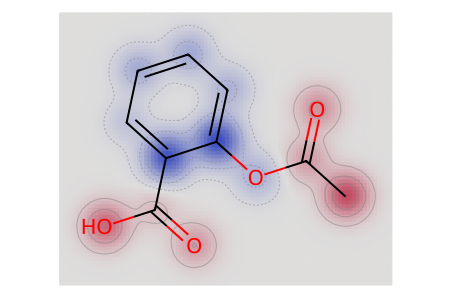


  FEATURE ATTRIBUTION MAP: IBUPROFEN
  Predicted logS: -3.126 | Substructure Attribution


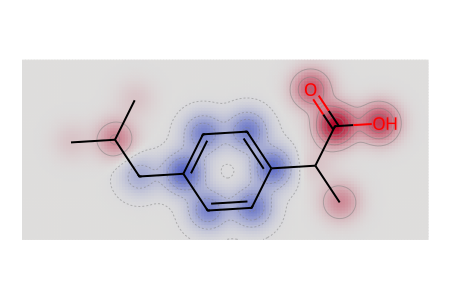

In [34]:
from rdkit import Chem
from rdkit.Chem.Draw import SimilarityMaps, rdMolDraw2D
from IPython.display import Image, display
import torch

def explain_prediction(smiles_str, mol_name="Molecule"):
    mol = Chem.MolFromSmiles(smiles_str)
    if mol is None:
        return

    # 1. Baseline prediction with full molecule
    data = smiles_to_graph(smiles_str).to(device)
    batch_idx = torch.zeros(data.x.size(0), dtype=torch.long, device=device)
    model.eval()
    with torch.no_grad():
        base_pred = model(data.x, data.edge_index, data.edge_weight, batch_idx, data.tabular).item()

    # 2. Atom-level occlusion saliency
    atom_weights = []
    for i in range(mol.GetNumAtoms()):
        x_masked = data.x.clone()
        x_masked[i] = 0.0  # Zero out node features for atom i
        with torch.no_grad():
            masked_pred = model(x_masked, data.edge_index, data.edge_weight, batch_idx, data.tabular).item()
        impact = base_pred - masked_pred
        atom_weights.append(float(impact))

    print(f"\n{'='*55}")
    print(f"  FEATURE ATTRIBUTION MAP: {mol_name.upper()}")
    print(f"  Predicted logS: {base_pred:.3f} | Substructure Attribution")
    print(f"{'='*55}")

    # 3. Create RDKit 2D Draw Canvas and render similarity heatmap
    drawer = rdMolDraw2D.MolDraw2DCairo(450, 300)
    SimilarityMaps.GetSimilarityMapFromWeights(
        mol,
        weights=atom_weights,
        draw2d=drawer,
        colorMap='coolwarm',
        contourLines=10
    )
    drawer.FinishDrawing()

    # 4. Display image in notebook
    display(Image(drawer.GetDrawingText()))

# Run interpretability visualizations on sample molecules
explain_prediction("CC(=O)Oc1ccccc1C(=O)O", "Aspirin")
explain_prediction("CC(C)Cc1ccc(cc1)C(C)C(=O)O", "Ibuprofen")